# Quiet Sun, 3 December 2015 — is this Sharma & Oberoi 2020 Figure 4?

A walk-through you can run cell by cell in front of other people.

**The question.** For a very quiet Sun, 03:39–03:44 UT, can we remake the radio maps *and* the brightness in kelvin, and see what agrees with Sharma & Oberoi (2020, ApJ 903, 126) and what does not?

**The short answer, so nobody is misled while we go through the steps:**

| | 108 MHz | 162 MHz | 217 MHz |
|---|---|---|---|
| Paper caption, peak | 0.92 million K | 1.20 | 1.50 |
| Our maps after the paper’s flux method | **0.89** | 1.00 | 1.06 |
| Same as the paper? | **yes, at 108 MHz** | not yet | not yet |

Shape (disk + western patch, larger radio Sun at 108 MHz) matches at every frequency. The kelvin scale matches the caption at 108 MHz once we use the Haslam 1982 sky *behind this Sun*, not a table from a different day. 162 and 217 MHz are still low. We will show why.

**How to use this.** Run the cells in order. The markdown above each code cell is what to say. The comments in the code are for you, not for the plot. Kernel: `solar-burst-multiview`. Start Jupyter in `notebooks/` or the repo root. Nothing here talks to the cluster.


## 1. Tools

Nothing is plotted yet. This cell only loads libraries.


In [1]:
from pathlib import Path
import json
import sys
import warnings

import numpy as np
import matplotlib.pyplot as plt
from astropy.coordinates import AltAz, EarthLocation, Galactic, SkyCoord, get_body
from astropy.time import Time
from astropy.io import fits
from astropy.wcs import FITSFixedWarning
import astropy.units as u
from IPython.display import Image, display
from matplotlib.patches import Circle, Ellipse

warnings.filterwarnings("ignore", category=FITSFixedWarning)
%matplotlib inline
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 11


## 2. Find the project folder

Works whether Jupyter was started in `notebooks/` or at the repo root.


In [2]:
here = Path.cwd()
if (here / "src" / "solarburst").exists():
    ROOT = here
elif (here.parent / "src" / "solarburst").exists():
    ROOT = here.parent
else:
    raise SystemExit("Cannot find src/solarburst. Open the notebook from the repo.")

src = ROOT / "src"
if str(src) not in sys.path:
    sys.path.insert(0, str(src))

from solarburst.haslam import HASLAM_ALPHA, HASLAM_CITE, HaslamMap, haslam_path
from solarburst.maps import (
    frequency_hz,
    header_cell_arcsec,
    hpc_extent,
    jybeam_to_tb,
    load_casa_2d,
    solar_pixel,
)
from solarburst.mohan2017 import scale_image

print("project folder:", ROOT)


project folder: /Users/csillag/Projects/solar-burst-multiview


## 3. Check that the files are on disk

If a line says **MISSING**, stop — that picture or table was not copied from the cluster yet. The Haslam map lives under `data/` (gitignored); the PNG of it is in `figures/`.


In [3]:
PATHS = {
    "our reconstruction of Figure 4": ROOT / "figures" / "sharma2020" / "fig4.png",
    "same maps, paper flux scale": ROOT / "figures" / "sharma2020" / "fig4_paper.png",
    "Haslam sky at this pointing": ROOT / "figures" / "sharma2020" / "haslam_sky.png",
    "Rohit 4-minute average": ROOT / "data" / "quiet2015" / "fig4_means.npz",
    "whole-Sun flux tables": ROOT / "data" / "quiet2015" / "paper_flux",
    "Haslam 1982 FITS": haslam_path(),
    "WSClean 4-minute pictures": ROOT / "data" / "quiet2015" / "wsclean",
    "CASA half-second pictures": ROOT / "data" / "quiet2015" / "paper_casa",
    "WSClean half-second pictures": ROOT / "data" / "quiet2015" / "paper_wsclean",
}
for name, path in PATHS.items():
    ok = path.exists()
    extra = f"  ({len(list(path.glob('*')))} files)" if path.is_dir() and ok else ""
    print(f"{'ok      ' if ok else 'MISSING '}  {name:36s}  {path}{extra}")


ok        our reconstruction of Figure 4        /Users/csillag/Projects/solar-burst-multiview/figures/sharma2020/fig4.png
ok        same maps, paper flux scale           /Users/csillag/Projects/solar-burst-multiview/figures/sharma2020/fig4_paper.png
ok        Haslam sky at this pointing           /Users/csillag/Projects/solar-burst-multiview/figures/sharma2020/haslam_sky.png
ok        Rohit 4-minute average                /Users/csillag/Projects/solar-burst-multiview/data/quiet2015/fig4_means.npz
ok        whole-Sun flux tables                 /Users/csillag/Projects/solar-burst-multiview/data/quiet2015/paper_flux  (17 files)
ok        Haslam 1982 FITS                      /Users/csillag/Projects/solar-burst-multiview/data/haslam/lambda_haslam408_nofilt.fits
ok        WSClean 4-minute pictures             /Users/csillag/Projects/solar-burst-multiview/data/quiet2015/wsclean  (4 files)
ok        CASA half-second pictures             /Users/csillag/Projects/solar-burst-multiview/data/quie

## 4. Names we will keep using

| Word | Meaning |
|---|---|
| **Rohit** | Rohit Sharma, first author. His processed pictures. |
| **CASA** | The picture-making program the 2020 paper used. |
| **WSClean** | A different program. We used it as a check. The paper did not. |
| **Half-second frame** | The telescope wrote a new picture every 0.5 s for four minutes (~570 pictures). |
| **4-minute average** | All of those frames stacked. That is the top of Figure 4. |
| **Whole-Sun brightness** | One number per frequency, in solar flux units: how bright the *entire* Sun is, measured from the antenna pairings *without* making a map. |
| **Haslam map** | The 408 MHz picture of the whole radio sky (Haslam et al. 1982). It is the Milky Way, not the Sun. Oberoi 2017 uses it as the sky *behind* the Sun. |
| **Million K** | Brightness temperature. Quiet corona is roughly 0.5–1.5 million K in this band. |

Four frequencies: **108, 162, 217, 240 MHz**. The paper’s Figure 4 top row uses the first three.


In [4]:
BANDS = ("108", "162", "217", "240")
PAPER_PEAKS = {"108": 0.92, "162": 1.20, "217": 1.50, "240": None}  # million K
RSUN = 958.0    # optical solar radius, arcsec
FOV = 2500.0    # half-width of the square we plot, arcsec
NPIX = 100      # crop size (50 arcsec / pixel → 5000 arcsec field)
CHAN = {"108": "084-085", "162": "125-126", "217": "169-170", "240": "187-188"}
FREQ_HZ = {"108": 108.14e6, "162": 160.62e6, "217": 216.94e6, "240": 239.98e6}


## 5. One drawing helper

Brown rings = 1× and 2× the optical Sun, centred on the Sun. Colour 0–1.7 million K when we compare to Figure 4; stretched to the panel’s own peak when we only care about shape. Run once, then forget it.


In [5]:
def draw_map(ax, tb, extent, beam, title, *, stretch_to_peak=False):
    """Radio map in kelvin. Rings sit on the optical Sun at (0, 0)."""
    tb_mk = np.asarray(tb, dtype=float) / 1e6
    peak = float(np.nanmax(tb_mk))
    if stretch_to_peak:
        cut, vmax = 0.12 * peak, max(peak, 1e-6)
    else:
        cut, vmax = 0.2, 1.7  # same cut and ceiling as Figure 4
    shown = np.where(tb_mk > cut, tb_mk, np.nan)
    ax.imshow(shown, origin="lower", extent=extent, cmap="jet",
              vmin=0.0, vmax=vmax, interpolation="nearest")
    if peak > 0:
        ax.contour(
            tb_mk,
            levels=[f * peak for f in (0.70, 0.75, 0.80, 0.85, 0.90, 0.95)],
            extent=extent, origin="lower", colors="black", linewidths=0.6,
        )
    for r in (1.0, 2.0):
        ax.add_patch(Circle((0.0, 0.0), r * RSUN, fill=False, color="saddlebrown", lw=1.2))
    bmaj, bmin, bpa = beam
    ax.add_patch(Ellipse(
        (-0.8 * FOV, -0.8 * FOV), bmin * 3600, bmaj * 3600,
        angle=-bpa, fill=False, color="black", lw=1.0,
    ))
    ax.set_xlim(-FOV, FOV)
    ax.set_ylim(-FOV, FOV)
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.text(
        0.03, 0.97, f"peak {peak:.2f} million K",
        transform=ax.transAxes, va="top", fontsize=9, color="white",
        bbox=dict(boxstyle="round,pad=0.15", fc="black", alpha=0.45, lw=0),
    )
    return peak


---

# Part A — What Rohit’s pictures look like

These are the maps already in his archive, averaged over the four minutes. This is **not** a photocopy of the journal figure. Same observation, same style.


## 6. Look at our reconstruction of Figure 4 first

Top: radio Sun at 108, 162, 217 MHz. Middle: a thermal model (FORWARD), not a telescope picture. Bottom: extreme ultraviolet, with radio contours.

The kelvin numbers on the **top** row here still use a later fudge factor (9.48), not the 2020 paper’s flux method. We fix that in Part C.


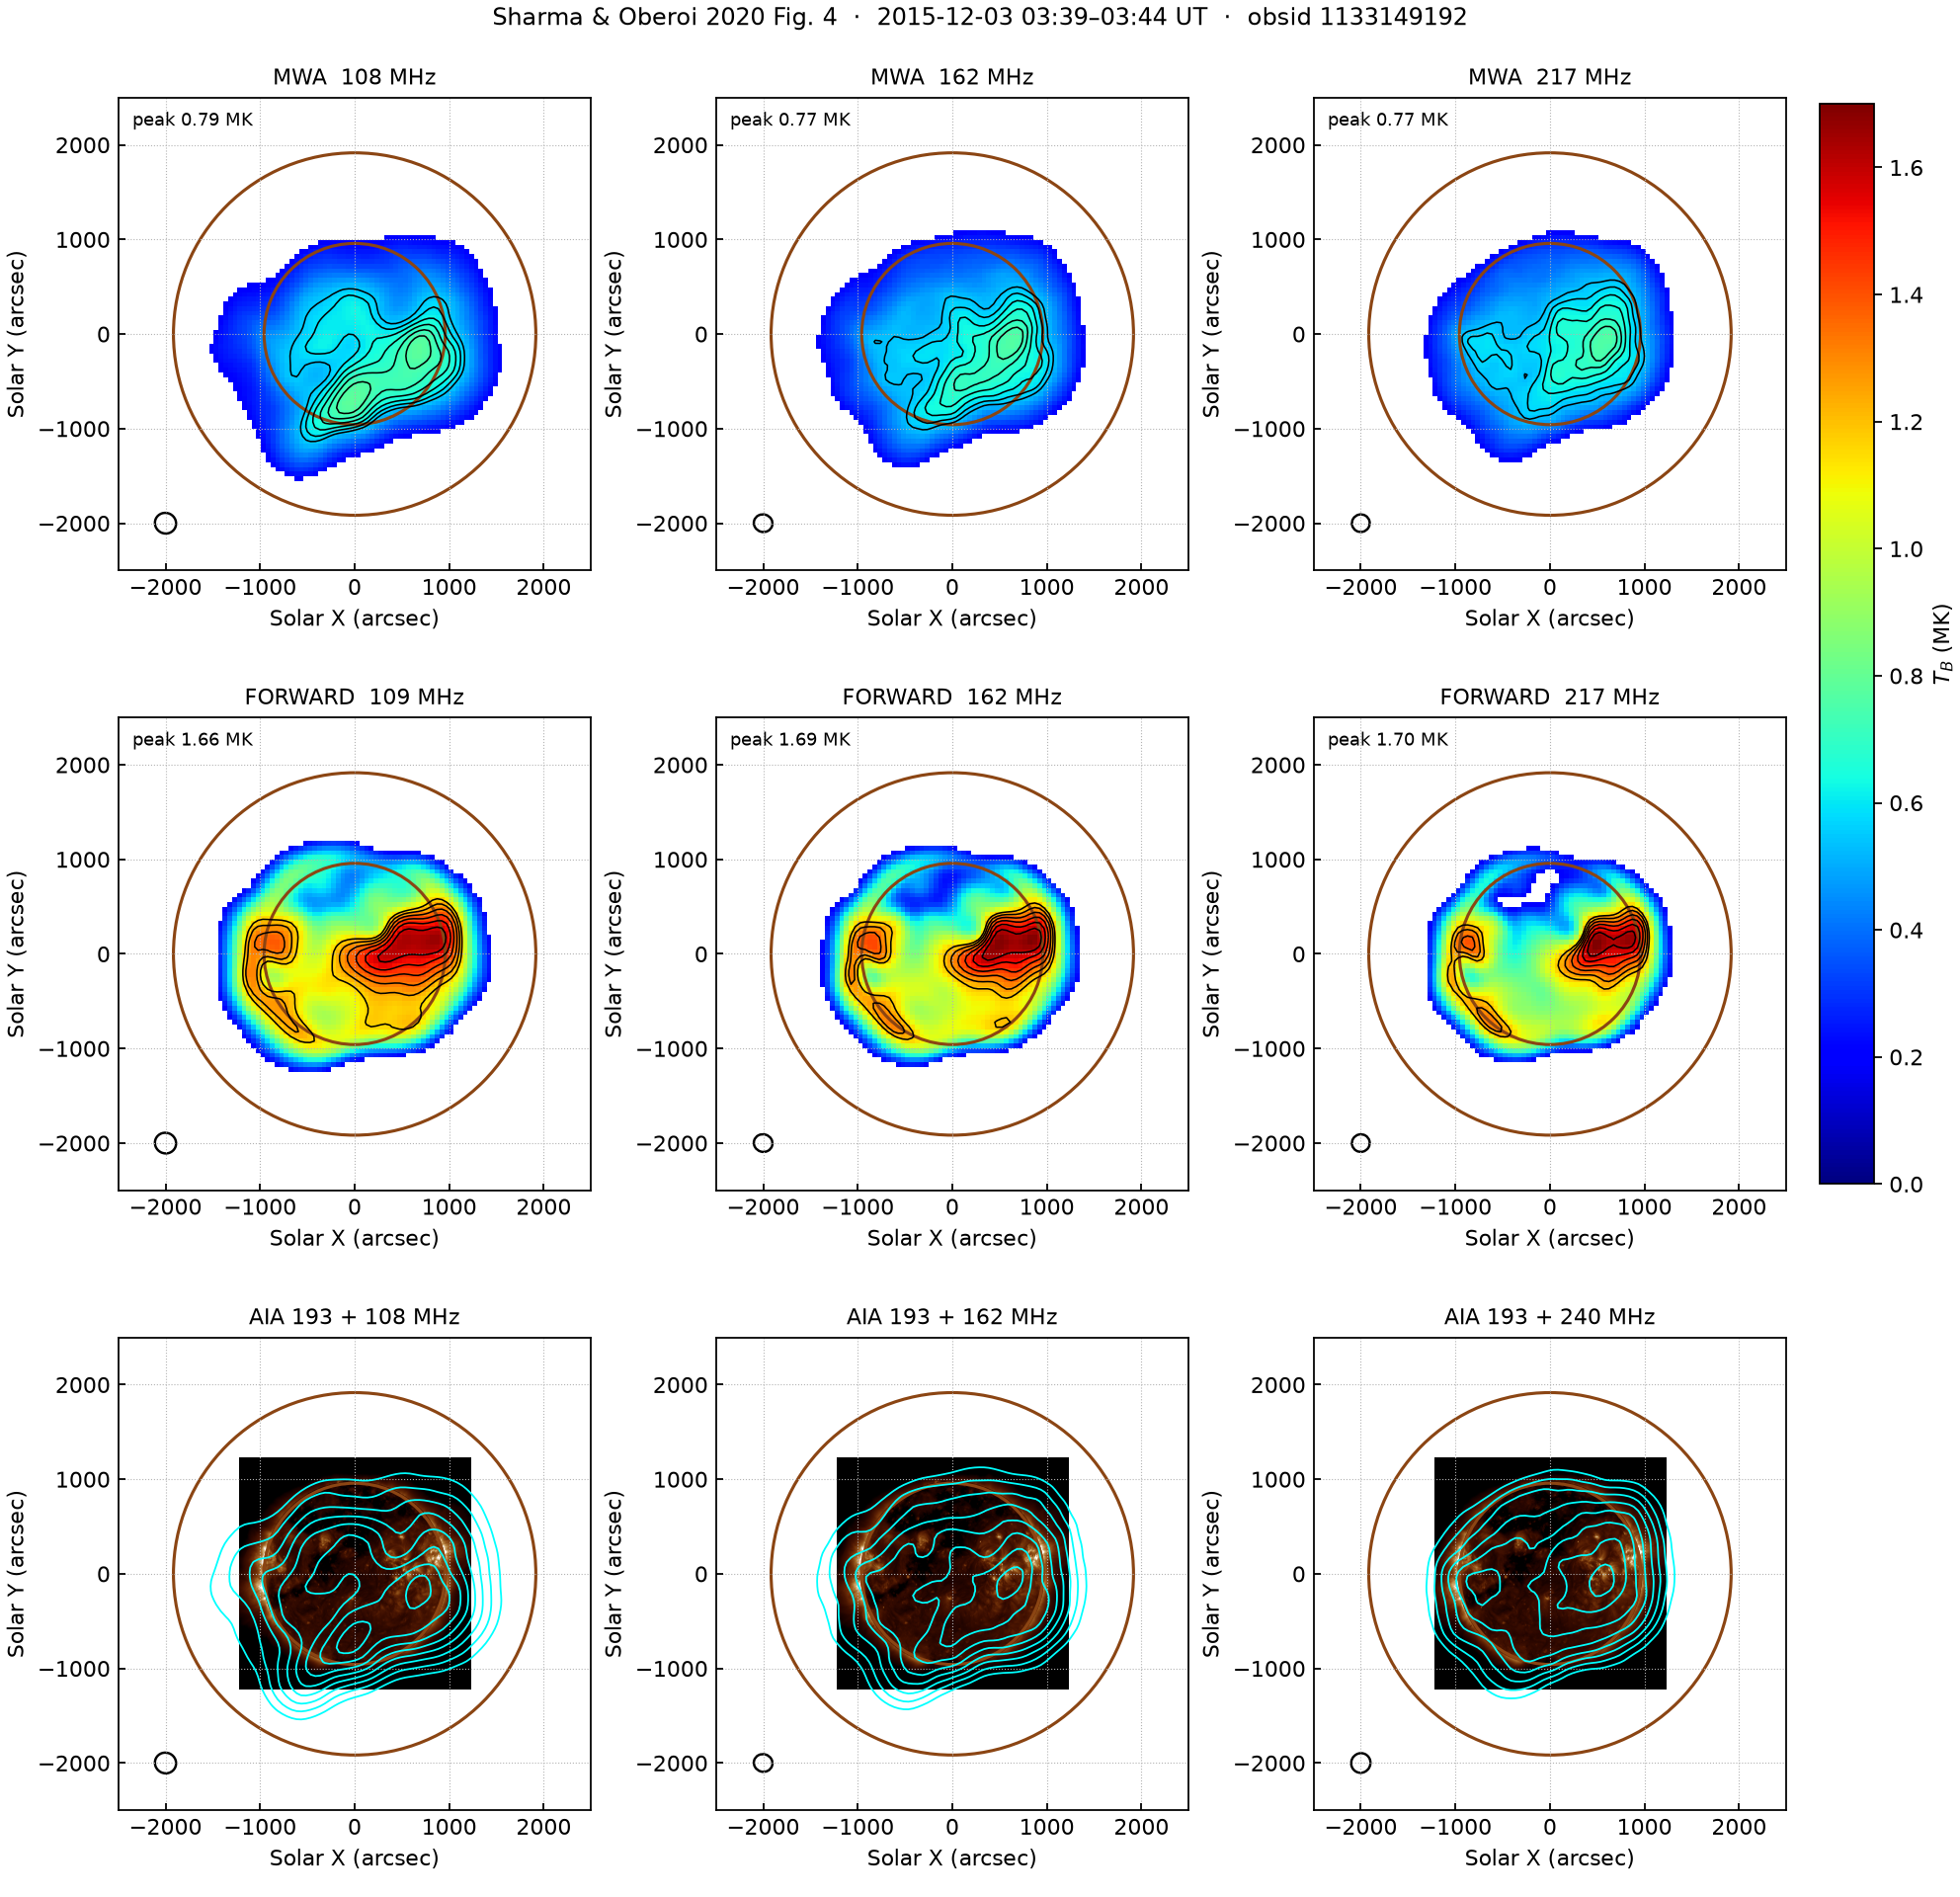

/Users/csillag/Projects/solar-burst-multiview/figures/sharma2020/fig4.png


In [6]:
fig4 = PATHS["our reconstruction of Figure 4"]
display(Image(filename=str(fig4), width=900))
print(fig4)


## 7. Load Rohit’s 4-minute average

Kelvin here includes fudge factor **9.48** (matched to his 2022 stored cubes). That is **not** the 2020 method. We keep a copy of the unscaled brightness (`jy`) so we can recolour later.


In [7]:
packed = np.load(PATHS["Rohit 4-minute average"])
rohit = {}
print(f"{'freq':>8s}  {'peak, million K':>16s}  {'paper caption':>14s}")
for lab in BANDS:
    ch = CHAN[lab]
    hdr = fits.Header()
    hdr["BMAJ"] = float(packed[f"{ch}_bmaj"])
    hdr["BMIN"] = float(packed[f"{ch}_bmin"])
    hdr["BPA"] = float(packed[f"{ch}_bpa"])
    hdr["CDELT1"] = -50.0 / 3600.0
    hdr["CDELT2"] = 50.0 / 3600.0
    hdr["CRPIX1"] = (NPIX + 1) / 2.0   # crop is centred on the Sun
    hdr["CRPIX2"] = (NPIX + 1) / 2.0
    tb = np.asarray(packed[f"{ch}_tb"], dtype=float)
    # Undo 9.48 → brightness in Jy/beam on an arbitrary scale.
    jy = tb / jybeam_to_tb(np.ones(1), FREQ_HZ[lab], hdr["BMAJ"], hdr["BMIN"], scale=9.48)[0]
    rohit[lab] = {
        "tb": tb, "jy": jy, "header": hdr,
        "beam": (hdr["BMAJ"], hdr["BMIN"], hdr["BPA"]),
        "extent": np.asarray(packed[f"{ch}_extent"], dtype=float),
        "freq_hz": FREQ_HZ[lab],
    }
    cap = PAPER_PEAKS[lab]
    cap_s = f"{cap:.2f}" if cap else "—"
    print(f"{lab:>5s} MHz  {tb.max()/1e6:16.3f}  {cap_s:>14s}")


    freq   peak, million K   paper caption
  108 MHz             0.788            0.92
  162 MHz             0.770            1.20
  217 MHz             0.765            1.50
  240 MHz             0.449               —


## 8. One map: 108 MHz

Look at: a radio disk **larger** than the optical Sun (inner brown ring), and a brighter patch on the **west** (right). That is the quiet-Sun shape in the paper.


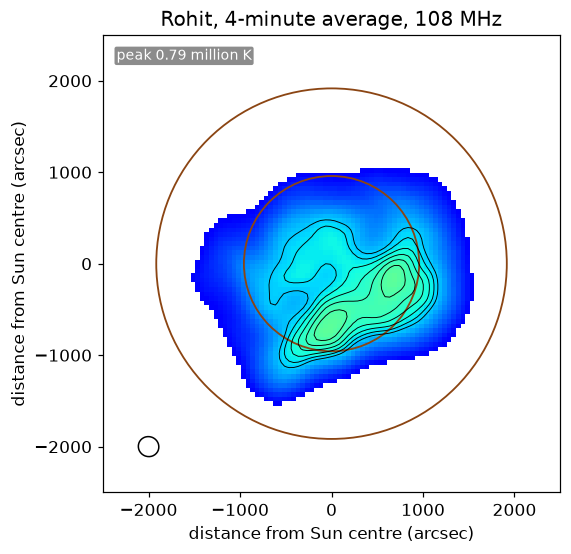

In [8]:
fig, ax = plt.subplots(figsize=(5.4, 5.4))
draw_map(
    ax, rohit["108"]["tb"], rohit["108"]["extent"], rohit["108"]["beam"],
    "Rohit, 4-minute average, 108 MHz",
)
ax.set_xlabel("distance from Sun centre (arcsec)")
ax.set_ylabel("distance from Sun centre (arcsec)")
plt.show()


## 9. All four frequencies, same colour scale as Figure 4

0–1.7 million K. Compare the printed peak to the caption (108 / 162 / 217 MHz: 0.92 / 1.20 / 1.50). These peaks are still on the 9.48 fudge — they are **not** supposed to match the caption yet.


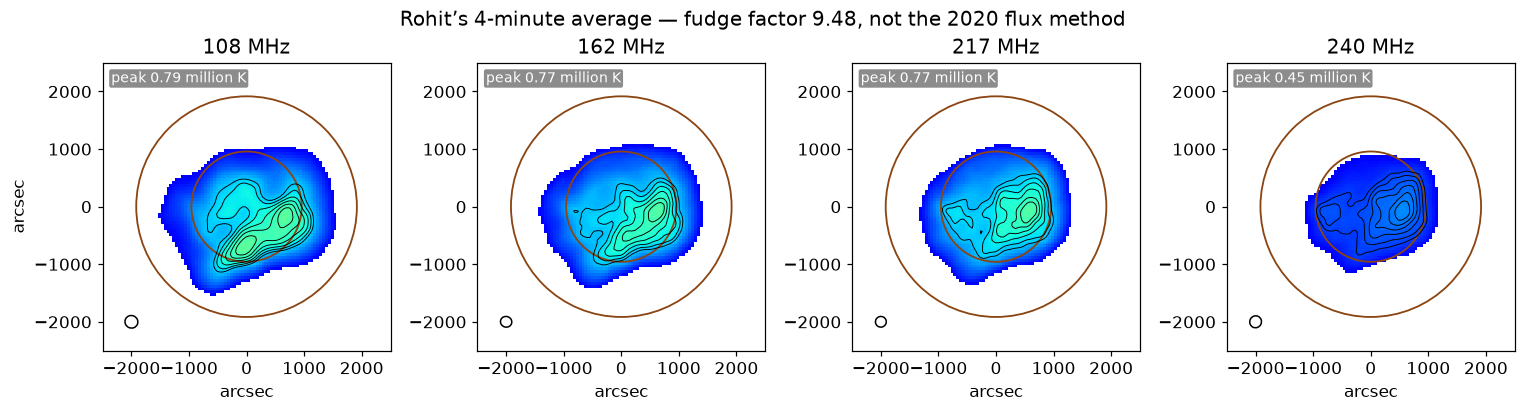

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, lab in zip(axes, BANDS):
    draw_map(ax, rohit[lab]["tb"], rohit[lab]["extent"], rohit[lab]["beam"], f"{lab} MHz")
    ax.set_xlabel("arcsec")
axes[0].set_ylabel("arcsec")
fig.suptitle("Rohit’s 4-minute average — fudge factor 9.48, not the 2020 flux method")
plt.tight_layout()
plt.show()


---

# Part B — The sky behind the Sun (Haslam 1982)

The 2020 paper does **not** set kelvin from a calibrator star. It does two steps:

1. Measure how bright the **whole Sun** is from the shortest antenna pairings (Oberoi, Sharma & Rogers 2017). One number per frequency, in solar flux units.
2. Stretch the map so the disk adds up to that number, then convert to kelvin (Mohan & Oberoi 2017).

Step 1 needs the radio sky *around* the Sun, because the antennas see the Milky Way as well. That sky model is the Haslam et al. 1982 408 MHz survey — the same map Oberoi 2017 cites — scaled with spectral index −2.55.

It is **not** a picture of the Sun. It is the Galaxy.


## 10. Open the Haslam map and read a few directions

Galactic centre = bright. North Galactic pole = faint. Then the direction of *this* Sun, 3 December 2015, 03:42 UT.


In [10]:
haslam_fits = PATHS["Haslam 1982 FITS"]
if not haslam_fits.exists():
    raise SystemExit(
        f"{haslam_fits} is missing. From the repo root:\n"
        "  python scripts/sharma2020_haslam_tsky.py"
    )

sky = HaslamMap(haslam_fits)
info = sky.info()
print("Haslam 1982 map —", HASLAM_CITE)
print(f"  file     {haslam_fits.name}")
print(f"  pixels   nside={info['nside']}, {info['npix']} pixels, {info['order']}")
print(f"  T at 408 MHz: {info['t408_K_min']:.0f}–{info['t408_K_max']:.0f} K  "
      f"(median {info['t408_K_median']:.0f} K)")

# Three directions on the sky, in kelvin at 408 MHz and scaled to 108 MHz.
gc = SkyCoord(l=0 * u.deg, b=0 * u.deg, frame=Galactic())
ngp = SkyCoord(l=0 * u.deg, b=90 * u.deg, frame=Galactic())
mro = EarthLocation.of_site("MWA")
when = Time("2015-12-03T03:42:04")
sun = get_body("sun", when, location=mro)
sun_altaz = sun.transform_to(AltAz(obstime=when, location=mro))
# Direction we actually look (local alt-az → Galactic), not the 3-D vector to the Sun.
sun_dir = SkyCoord(
    az=sun_altaz.az, alt=sun_altaz.alt,
    frame=AltAz(obstime=when, location=mro),
).transform_to(Galactic())

print(f"\nSun at this moment: az {sun_altaz.az.deg:.1f}°, altitude {sun_altaz.alt.deg:.1f}°")
print(f"that direction in Galactic coordinates: l={sun_dir.l.deg:.1f}°, b={sun_dir.b.deg:.1f}°")
print("(b near 0° means we are looking toward the Milky Way, not away from it.)")
print()
print(f"{'where':<28s}  {'T at 408 MHz':>12s}  {'T at 108 MHz':>12s}")
for name, coord in (
    ("Galactic centre", gc),
    ("North Galactic pole", ngp),
    ("this Sun, 3 Dec 2015", sun_dir),
):
    t408 = float(sky.at_408(coord))
    t108 = float(sky.at_freq(coord, 108.14e6))
    print(f"{name:<28s}  {t408:10.0f} K  {t108:10.0f} K")


Haslam 1982 map — Haslam et al. 1982, A&AS 47, 1
  file     lambda_haslam408_nofilt.fits
  pixels   nside=512, 3145728 pixels, nested
  T at 408 MHz: 11–4817 K  (median 25 K)



Sun at this moment: az 46.5°, altitude 83.4°
that direction in Galactic coordinates: l=356.3°, b=16.9°
(b near 0° means we are looking toward the Milky Way, not away from it.)

where                         T at 408 MHz  T at 108 MHz
Galactic centre                     1926 K       56917 K
North Galactic pole                   21 K         608 K
this Sun, 3 Dec 2015                  58 K        1709 K


## 11. The sky above the horizon at 03:42 UT

Yellow dot = the Sun. It sits **on** the bright band of the Milky Way. That is why a table of sky temperatures from 3 September 2013 (Sun high above the Galactic plane) is the wrong sky for this morning.

White contours = the MWA tile beam (90 %, 9 %, 0.9 %). That beam is a 4×4 array of dipoles with the published tile geometry — the same layout Oberoi used. It is **not** their unpublished FEKO electromagnetic simulation.


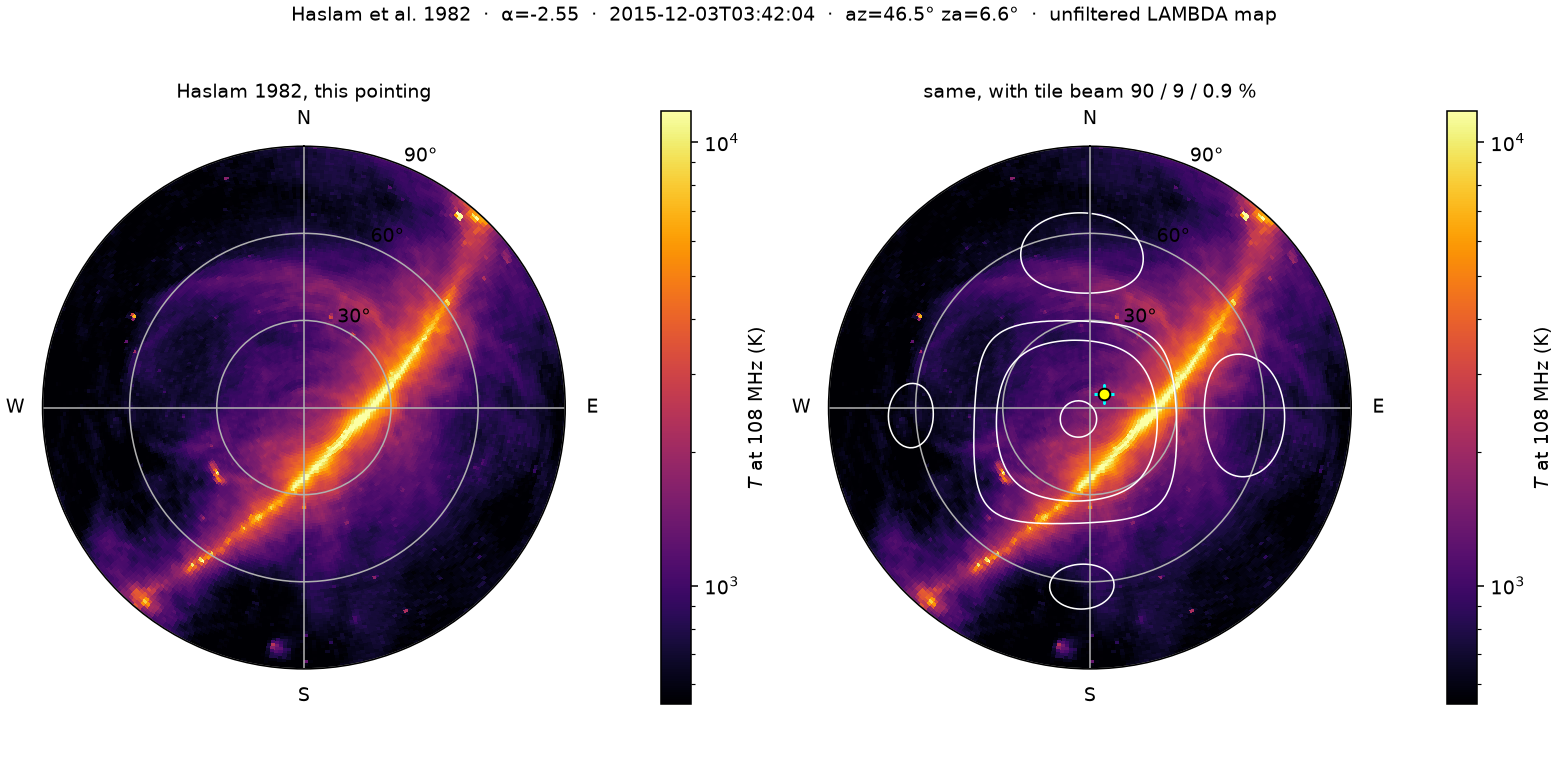

/Users/csillag/Projects/solar-burst-multiview/figures/sharma2020/haslam_sky.png


In [11]:
png = PATHS["Haslam sky at this pointing"]
display(Image(filename=str(png), width=920))
print(png)


## 12. Beam-averaged sky temperature vs Oberoi’s 2013 table

Oberoi’s Table 1 is *their* pointing on *their* day. We recompute the same integral (Haslam × tile beam) for **this** pointing. `T_Sky` is what goes into the whole-Sun flux. Hardware terms `T_Rec` and `T_Pick-up` stay on Table 1 — those are the receiver, not the sky.


In [12]:
flux_dir = PATHS["whole-Sun flux tables"]
print(f"{'freq':>6s}  {'T_Sky this morning':>18s}  {'T_Sky 2013 table':>16s}  {'ratio':>6s}")
for lab in BANDS:
    rec = json.loads((flux_dir / f"{lab}MHz_full.json").read_text())
    now = rec["t_sky_K"]
    old = rec["table1_t_sky_K"]
    print(f"{lab:>4s}  {now:15.0f} K  {old:13.0f} K  {now/old:6.2f}×")
print()
print("The sky behind this Sun is several times brighter than the 2013 table.")
print("That is the Haslam map at this pointing, not a different survey.")


  freq  T_Sky this morning  T_Sky 2013 table   ratio
 108             2191 K            550 K    3.98×
 162              699 K            212 K    3.29×
 217              300 K            144 K    2.08×
 240              218 K            140 K    1.56×

The sky behind this Sun is several times brighter than the 2013 table.
That is the Haslam map at this pointing, not a different survey.


---

# Part C — Whole-Sun brightness, then recolour the maps

From the recordings (no map needed): a normalised correlation `r_N` on the six shortest antenna pairings (Tile011, 021, 022, 023). Combined with `T_Sky` from Haslam, that gives the flux of the whole Sun, `S_⊙`, in solar flux units. Then we stretch Rohit’s pixels so the disk adds up to `S_⊙` and convert to kelvin.


## 13. The whole-Sun numbers

Blue = this observation, Haslam sky at this pointing. Grey = Oberoi’s 3 September 2013 day — a different quiet day, **not a target**. The middle column is the same `r_N` we measured, but with the 2013 table for `T_Sky`: that was the first pass, and it was too faint.


In [13]:
s_odot = {}
print(f"{'freq':>6s}  {'this morning':>12s}  {'same r_N, 2013 sky':>18s}  {'Oberoi 2013 day':>16s}")
check_2013 = {"108": 2.16, "162": 5.08, "217": 11.3, "240": 17.1}  # their Table 2, different day
for lab in BANDS:
    rec = json.loads((flux_dir / f"{lab}MHz_full.json").read_text())
    s_odot[lab] = rec["s_odot_sfu"]
    print(
        f"{lab:>4s}  {s_odot[lab]:12.2f}  {rec['table1_s_odot_sfu']:18.2f}  {check_2013[lab]:16.2f}"
    )


  freq  this morning  same r_N, 2013 sky   Oberoi 2013 day
 108          2.87                0.82              2.16
 162          6.50                2.21              5.08
 217         11.72                6.31             11.30
 240          8.17                5.74             17.10


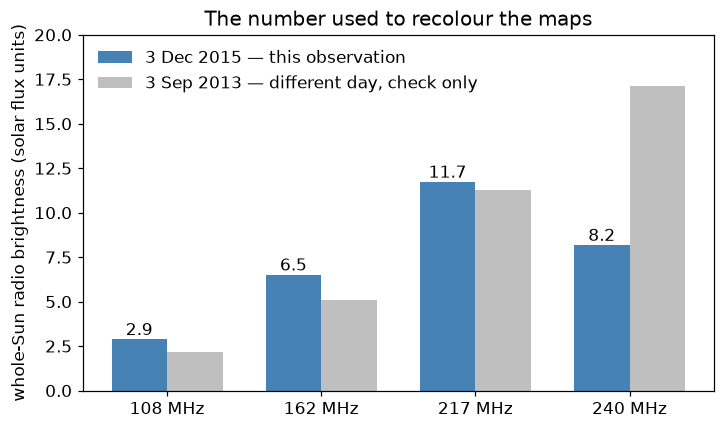

In [14]:
fig, ax = plt.subplots(figsize=(7.4, 4.2))
x = np.arange(len(BANDS))
ours = [s_odot[lab] for lab in BANDS]
ref = [check_2013[lab] for lab in BANDS]
ax.bar(x - 0.18, ours, 0.36, color="steelblue", label="3 Dec 2015 — this observation")
ax.bar(x + 0.18, ref, 0.36, color="0.75", label="3 Sep 2013 — different day, check only")
ax.set_xticks(x, [f"{lab} MHz" for lab in BANDS])
ax.set_ylabel("whole-Sun radio brightness (solar flux units)")
ax.set_title("The number used to recolour the maps")
ax.legend(frameon=False)
ax.set_ylim(0, 20)
for i, v in enumerate(ours):
    ax.text(i - 0.18, v + 0.25, f"{v:.1f}", ha="center")
plt.show()


## 14. Stretch Rohit’s maps so the disk equals that number

Same pixels as Part A. Only the colour changes. The stretch is “how far off was the map’s own disk sum from the whole-Sun number”.


In [15]:
paper_scaled = {}
print(f"{'freq':>6s}  {'row 1 peak':>10s}  {'row 2 peak':>10s}  {'caption':>8s}  {'stretch':>8s}")
for lab in BANDS:
    rec = scale_image(
        rohit[lab]["jy"],
        rohit[lab]["header"],
        s_odot[lab] * 1e4,   # solar flux units → jansky
        nsig=5.0,            # paper: disk = pixels above 5σ of the off-Sun noise
        freq_hz=rohit[lab]["freq_hz"],
    )
    rec["beam"] = rohit[lab]["beam"]
    rec["extent"] = rohit[lab]["extent"]
    paper_scaled[lab] = rec
    cap = PAPER_PEAKS[lab]
    cap_s = f"{cap:8.2f}" if cap else "     —"
    print(
        f"{lab:>4s}  {rohit[lab]['tb'].max()/1e6:10.3f}  {rec['tb_K'].max()/1e6:10.3f}  "
        f"{cap_s}  {rec['f_nu']:8.2f}"
    )


  freq  row 1 peak  row 2 peak   caption   stretch
 108       0.788       0.889      0.92     10.69
 162       0.770       0.996      1.20     12.25
 217       0.765       1.064      1.50     13.18
 240       0.449       0.621       —     13.10


## 15. Before / after at 108 MHz

Left = fudge factor 9.48. Right = whole-Sun brightness with the Haslam sky at this pointing. **The shape cannot change.** Only the colour numbers change. The right-hand peak should sit next to the caption, 0.92 million K.


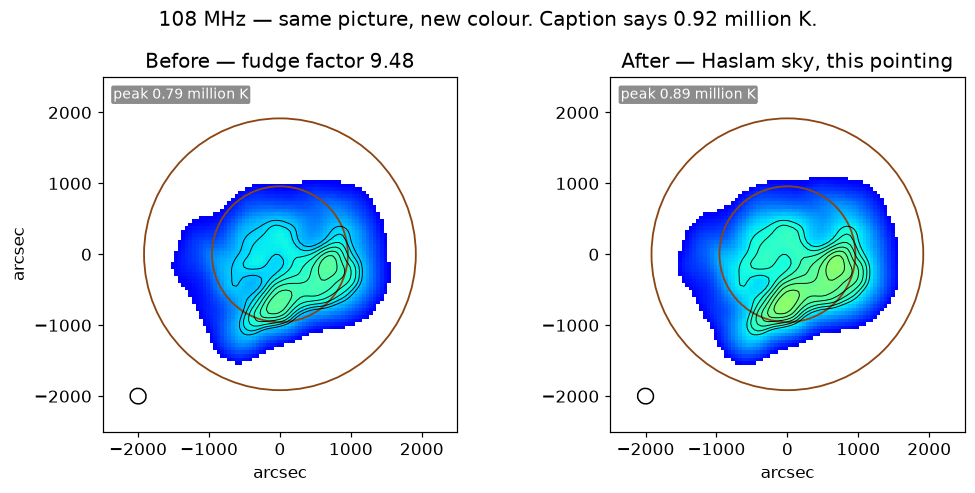

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.5))
draw_map(
    axes[0], rohit["108"]["tb"], rohit["108"]["extent"], rohit["108"]["beam"],
    "Before — fudge factor 9.48",
)
draw_map(
    axes[1], paper_scaled["108"]["tb_K"], paper_scaled["108"]["extent"],
    paper_scaled["108"]["beam"],
    "After — Haslam sky, this pointing",
    stretch_to_peak=False,
)
for ax in axes:
    ax.set_xlabel("arcsec")
axes[0].set_ylabel("arcsec")
fig.suptitle("108 MHz — same picture, new colour. Caption says 0.92 million K.")
plt.tight_layout()
plt.show()


## 16. All four frequencies on the paper colour scale

0–1.7 million K, same as Figure 4. 108 MHz should now match the caption. 162 and 217 MHz should still look a bit faint compared with 1.20 and 1.50.


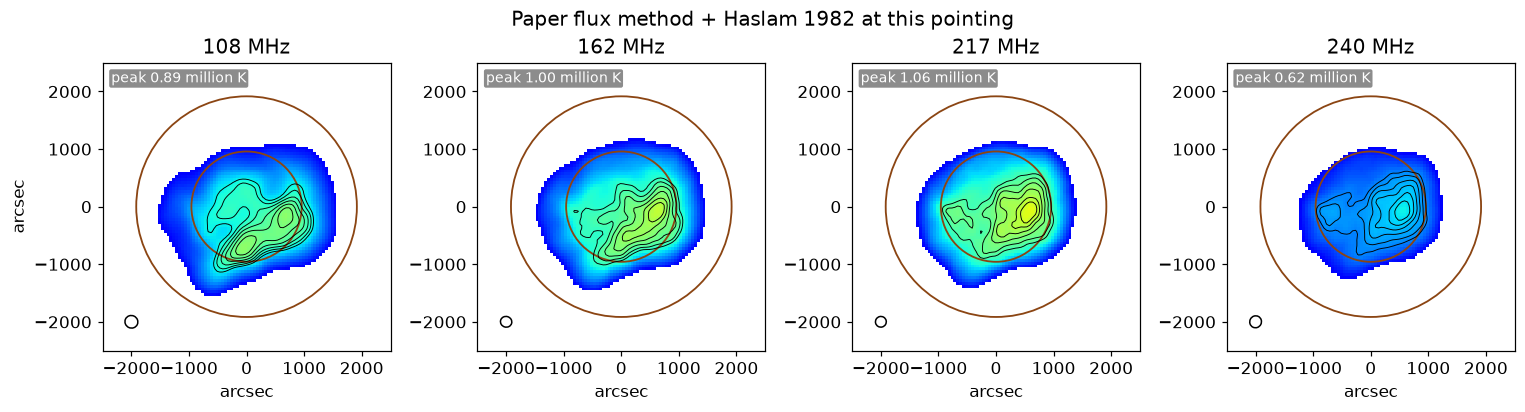

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, lab in zip(axes, BANDS):
    draw_map(
        ax, paper_scaled[lab]["tb_K"], paper_scaled[lab]["extent"],
        paper_scaled[lab]["beam"], f"{lab} MHz",
    )
    ax.set_xlabel("arcsec")
axes[0].set_ylabel("arcsec")
fig.suptitle("Paper flux method + Haslam 1982 at this pointing")
plt.tight_layout()
plt.show()


## 17. The three-row figure on the paper flux scale

This is the same layout as Figure 4 (MWA / FORWARD / AIA), with the Haslam whole-Sun numbers on the top row. It is **not** `fig4.png` and it is **not** a photocopy of the journal.


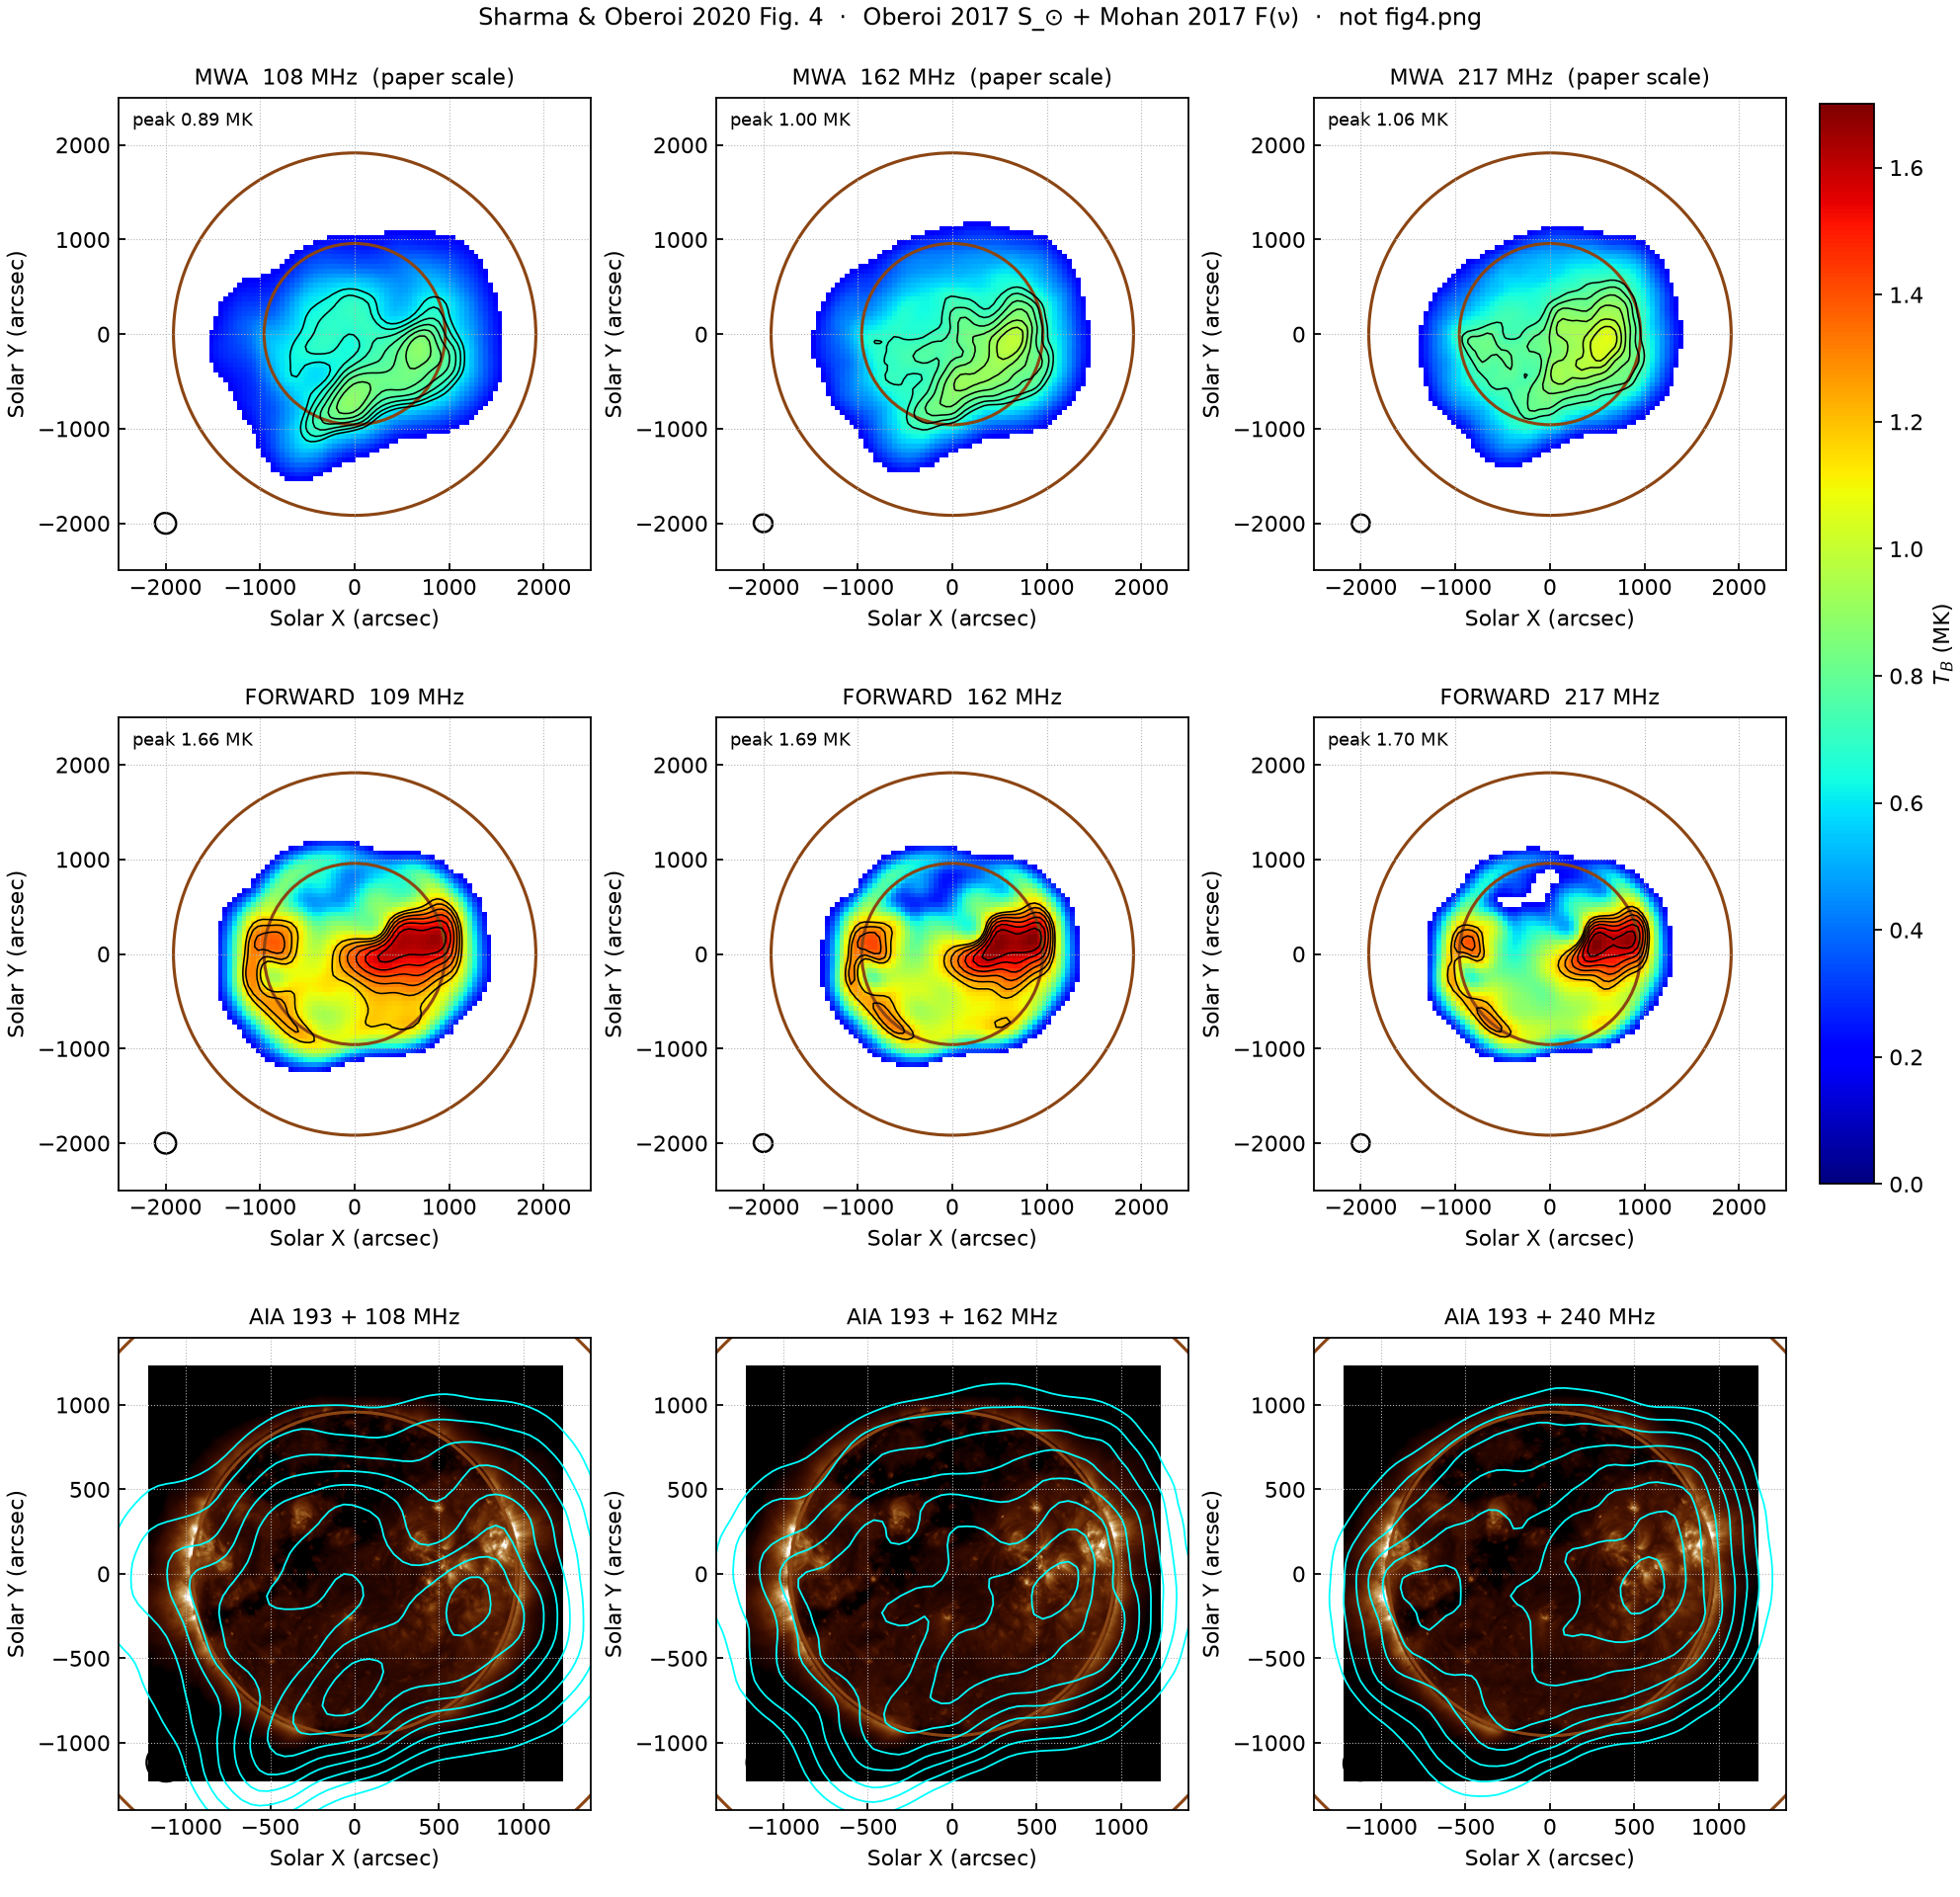

/Users/csillag/Projects/solar-burst-multiview/figures/sharma2020/fig4_paper.png


In [18]:
paper_fig = PATHS["same maps, paper flux scale"]
display(Image(filename=str(paper_fig), width=900))
print(paper_fig)


---

# Part D — Did we invent a different Sun?

We remade pictures from the visibilities with CASA (the paper’s program) and WSClean (ours). If the western patch is still on the west, we did not invent a different Sun. These rows are **not** on the paper kelvin scale yet — look at shape.


## 18. Crop on the Sun, not on the bright patch

The radio Sun is not in the middle of the large file. The brightest pixel is the western patch. Cropping on that pixel puts the patch at (0, 0) and the brown rings look wrong. That was a display bug, not a telescope pointing error.


image size 1024 × 1024 pixels
Sun (from the time in the header):  x=607, y=344
brightest pixel (western patch):    x=606, y=330
offset: -1 px in x, -14 px in y   (1 px = 50 arcsec)


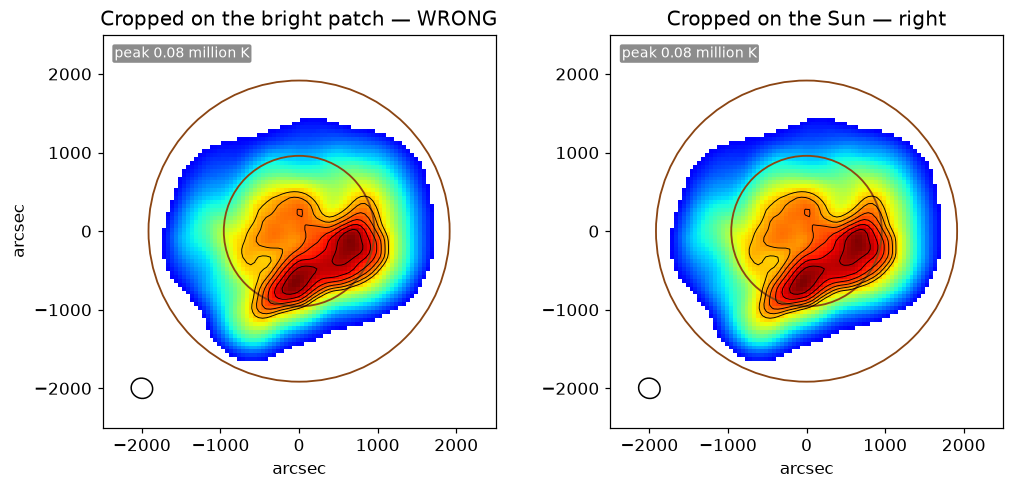

In [19]:
data, hdr = load_casa_2d(PATHS["WSClean 4-minute pictures"] / "108MHz-image.fits")
sx, sy = solar_pixel(hdr)
py, px = np.unravel_index(int(np.nanargmax(data)), data.shape)
print(f"image size {data.shape[1]} × {data.shape[0]} pixels")
print(f"Sun (from the time in the header):  x={sx:.0f}, y={sy:.0f}")
print(f"brightest pixel (western patch):    x={px:.0f}, y={py:.0f}")
print(f"offset: {px - sx:.0f} px in x, {py - sy:.0f} px in y   (1 px = 50 arcsec)")


def crop_at(data, hdr, cx, cy):
    x0 = int(round(cx - (NPIX - 1) / 2.0))
    y0 = int(round(cy - (NPIX - 1) / 2.0))
    crop = data[y0:y0 + NPIX, x0:x0 + NPIX]
    extent = hpc_extent(
        NPIX, NPIX, cell_arcsec=header_cell_arcsec(hdr),
        sun_xy=(sx, sy), origin=(x0, y0),
    )
    beam = (float(hdr["BMAJ"]), float(hdr["BMIN"]), float(hdr.get("BPA", 0.0)))
    tb = jybeam_to_tb(crop, frequency_hz(hdr), beam[0], beam[1], scale=1.0)
    return tb, extent, beam


tb_wrong, ext_wrong, beam = crop_at(data, hdr, px, py)
tb_right, ext_right, beam = crop_at(data, hdr, sx, sy)

fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.5))
draw_map(axes[0], tb_wrong, ext_wrong, beam, "Cropped on the bright patch — WRONG",
         stretch_to_peak=True)
draw_map(axes[1], tb_right, ext_right, beam, "Cropped on the Sun — right",
         stretch_to_peak=True)
for ax in axes:
    ax.set_xlabel("arcsec")
axes[0].set_ylabel("arcsec")
plt.tight_layout()
plt.show()


## 19. Load the remade pictures (always cropped on the Sun)

Kelvin from the Rayleigh–Jeans formula with **no** fudge and **no** whole-Sun stretch. Peaks will sit near 0.08 million K. That is expected. Look at **shape**.


In [20]:
def load_picture(path: Path) -> dict:
    data, hdr = load_casa_2d(path)
    sx, sy = solar_pixel(hdr)
    x0 = int(round(sx - (NPIX - 1) / 2.0))
    y0 = int(round(sy - (NPIX - 1) / 2.0))
    crop = data[y0:y0 + NPIX, x0:x0 + NPIX]
    extent = hpc_extent(
        NPIX, NPIX, cell_arcsec=header_cell_arcsec(hdr),
        sun_xy=(sx, sy), origin=(x0, y0),
    )
    beam = (float(hdr["BMAJ"]), float(hdr["BMIN"]), float(hdr.get("BPA", 0.0)))
    tb = jybeam_to_tb(crop, frequency_hz(hdr), beam[0], beam[1], scale=1.0)
    return {"tb": tb, "beam": beam, "extent": extent}


wsclean_4min = {
    lab: load_picture(PATHS["WSClean 4-minute pictures"] / f"{lab}MHz-image.fits")
    for lab in BANDS
}
casa_half = {
    lab: load_picture(PATHS["CASA half-second pictures"] / f"{lab}MHz_mid.fits")
    for lab in BANDS
}
wsclean_half = {
    lab: load_picture(PATHS["WSClean half-second pictures"] / f"{lab}MHz_mid-image.fits")
    for lab in BANDS
}
print("loaded remade pictures (WSClean 4 min, CASA 0.5 s, WSClean 0.5 s)")


loaded remade pictures (WSClean 4 min, CASA 0.5 s, WSClean 0.5 s)


## 20. Five versions at 108 MHz, side by side

Ask: is the western patch on the west? Does the disk sit in the inner brown ring? Only panel 1 uses the Figure 4 colour scale; the others stretch to their own peak so the shape is visible.


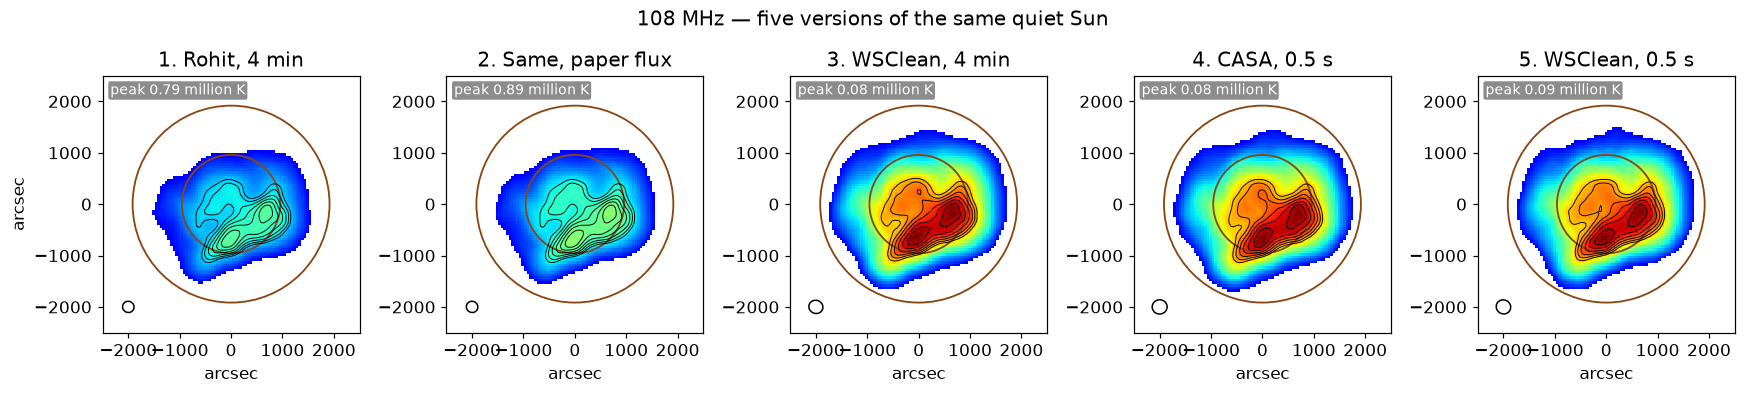

In [21]:
def five_versions(lab: str) -> None:
    panels = [
        ("1. Rohit, 4 min", rohit[lab]["tb"], rohit[lab]["extent"], rohit[lab]["beam"], False),
        ("2. Same, paper flux", paper_scaled[lab]["tb_K"], paper_scaled[lab]["extent"], paper_scaled[lab]["beam"], False),
        ("3. WSClean, 4 min", wsclean_4min[lab]["tb"], wsclean_4min[lab]["extent"], wsclean_4min[lab]["beam"], True),
        ("4. CASA, 0.5 s", casa_half[lab]["tb"], casa_half[lab]["extent"], casa_half[lab]["beam"], True),
        ("5. WSClean, 0.5 s", wsclean_half[lab]["tb"], wsclean_half[lab]["extent"], wsclean_half[lab]["beam"], True),
    ]
    fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
    for ax, (title, tb, extent, beam, stretch) in zip(axes, panels):
        draw_map(ax, tb, extent, beam, title, stretch_to_peak=stretch)
        ax.set_xlabel("arcsec")
    axes[0].set_ylabel("arcsec")
    fig.suptitle(f"{lab} MHz — five versions of the same quiet Sun")
    plt.tight_layout()
    plt.show()


five_versions("108")


## 21. Same five versions at 162 MHz

Change the frequency and rerun. Try `"217"` or `"240"` as well.


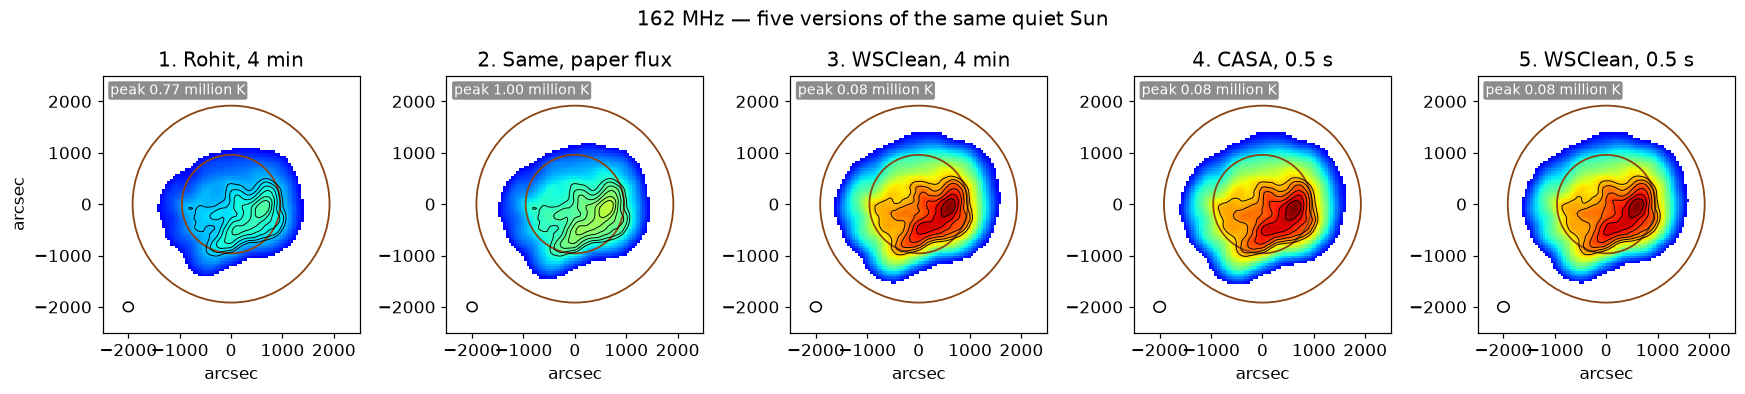

In [22]:
five_versions("162")


---

# Part E — What is the same, and what is not


## 22. Peak brightness, in million K

Row 2 is the one to compare with the paper caption. Rows 3–5 have no whole-Sun stretch yet.


In [23]:
print(f"{'freq':>6s}  {'caption':>8s}  {'Rohit 9.48':>10s}  {'paper method':>12s}  "
      f"{'WSClean 4 min':>13s}  {'CASA 0.5 s':>10s}  {'WSClean 0.5 s':>13s}")
for lab in BANDS:
    cap = PAPER_PEAKS[lab]
    cap_s = f"{cap:8.2f}" if cap else "     —"
    print(
        f"{lab:>4s}  {cap_s}  {rohit[lab]['tb'].max()/1e6:10.3f}  "
        f"{paper_scaled[lab]['tb_K'].max()/1e6:12.3f}  "
        f"{wsclean_4min[lab]['tb'].max()/1e6:13.3f}  "
        f"{casa_half[lab]['tb'].max()/1e6:10.3f}  "
        f"{wsclean_half[lab]['tb'].max()/1e6:13.3f}"
    )


  freq   caption  Rohit 9.48  paper method  WSClean 4 min  CASA 0.5 s  WSClean 0.5 s
 108      0.92       0.788         0.889          0.084       0.084          0.085
 162      1.20       0.770         0.996          0.083       0.081          0.082
 217      1.50       0.765         1.064          0.092       0.088          0.089
 240       —       0.449         0.621          0.051       0.048          0.049


## 23. What to say at the end

**Same as the paper**

- Quiet-Sun shape: disk plus a western compact source, larger radio Sun at 108 MHz.
- Remaking the pictures from the visibilities did not invent a different Sun.
- CASA and WSClean on the same half-second look alike, so the program is not the story.
- At **108 MHz**, after Haslam 1982 at *this* pointing, the peak is 0.89 million K against the caption 0.92.

**Not the same**

- 162 MHz: 1.00 vs 1.20. 217 MHz: 1.06 vs 1.50. Still low.
- The tile beam in the sky integral is a 4×4 array factor, not Oberoi’s unpublished FEKO patterns. Beam solid angle matches their table; far sidelobes at the bottom of the band are still a leftover.
- Rows 3–5 are still on a raw kelvin scale. Compare shape, not the printed peak.
- We averaged Rohit’s frames; we have not yet averaged many of *our* half-second CASA frames.

**Worth trying next**

- Put the whole-Sun number onto the remade CASA and WSClean pictures.
- Average many half-second CASA frames, as the paper did.
- FEKO embedded beam, if it ever turns up.

The sky we used is Haslam et al. 1982, unfiltered — the survey Oberoi 2017 cites — not a later reprocessing. The December Sun sits on the Milky Way; that, not a different map, is what moved 108 MHz onto the caption.


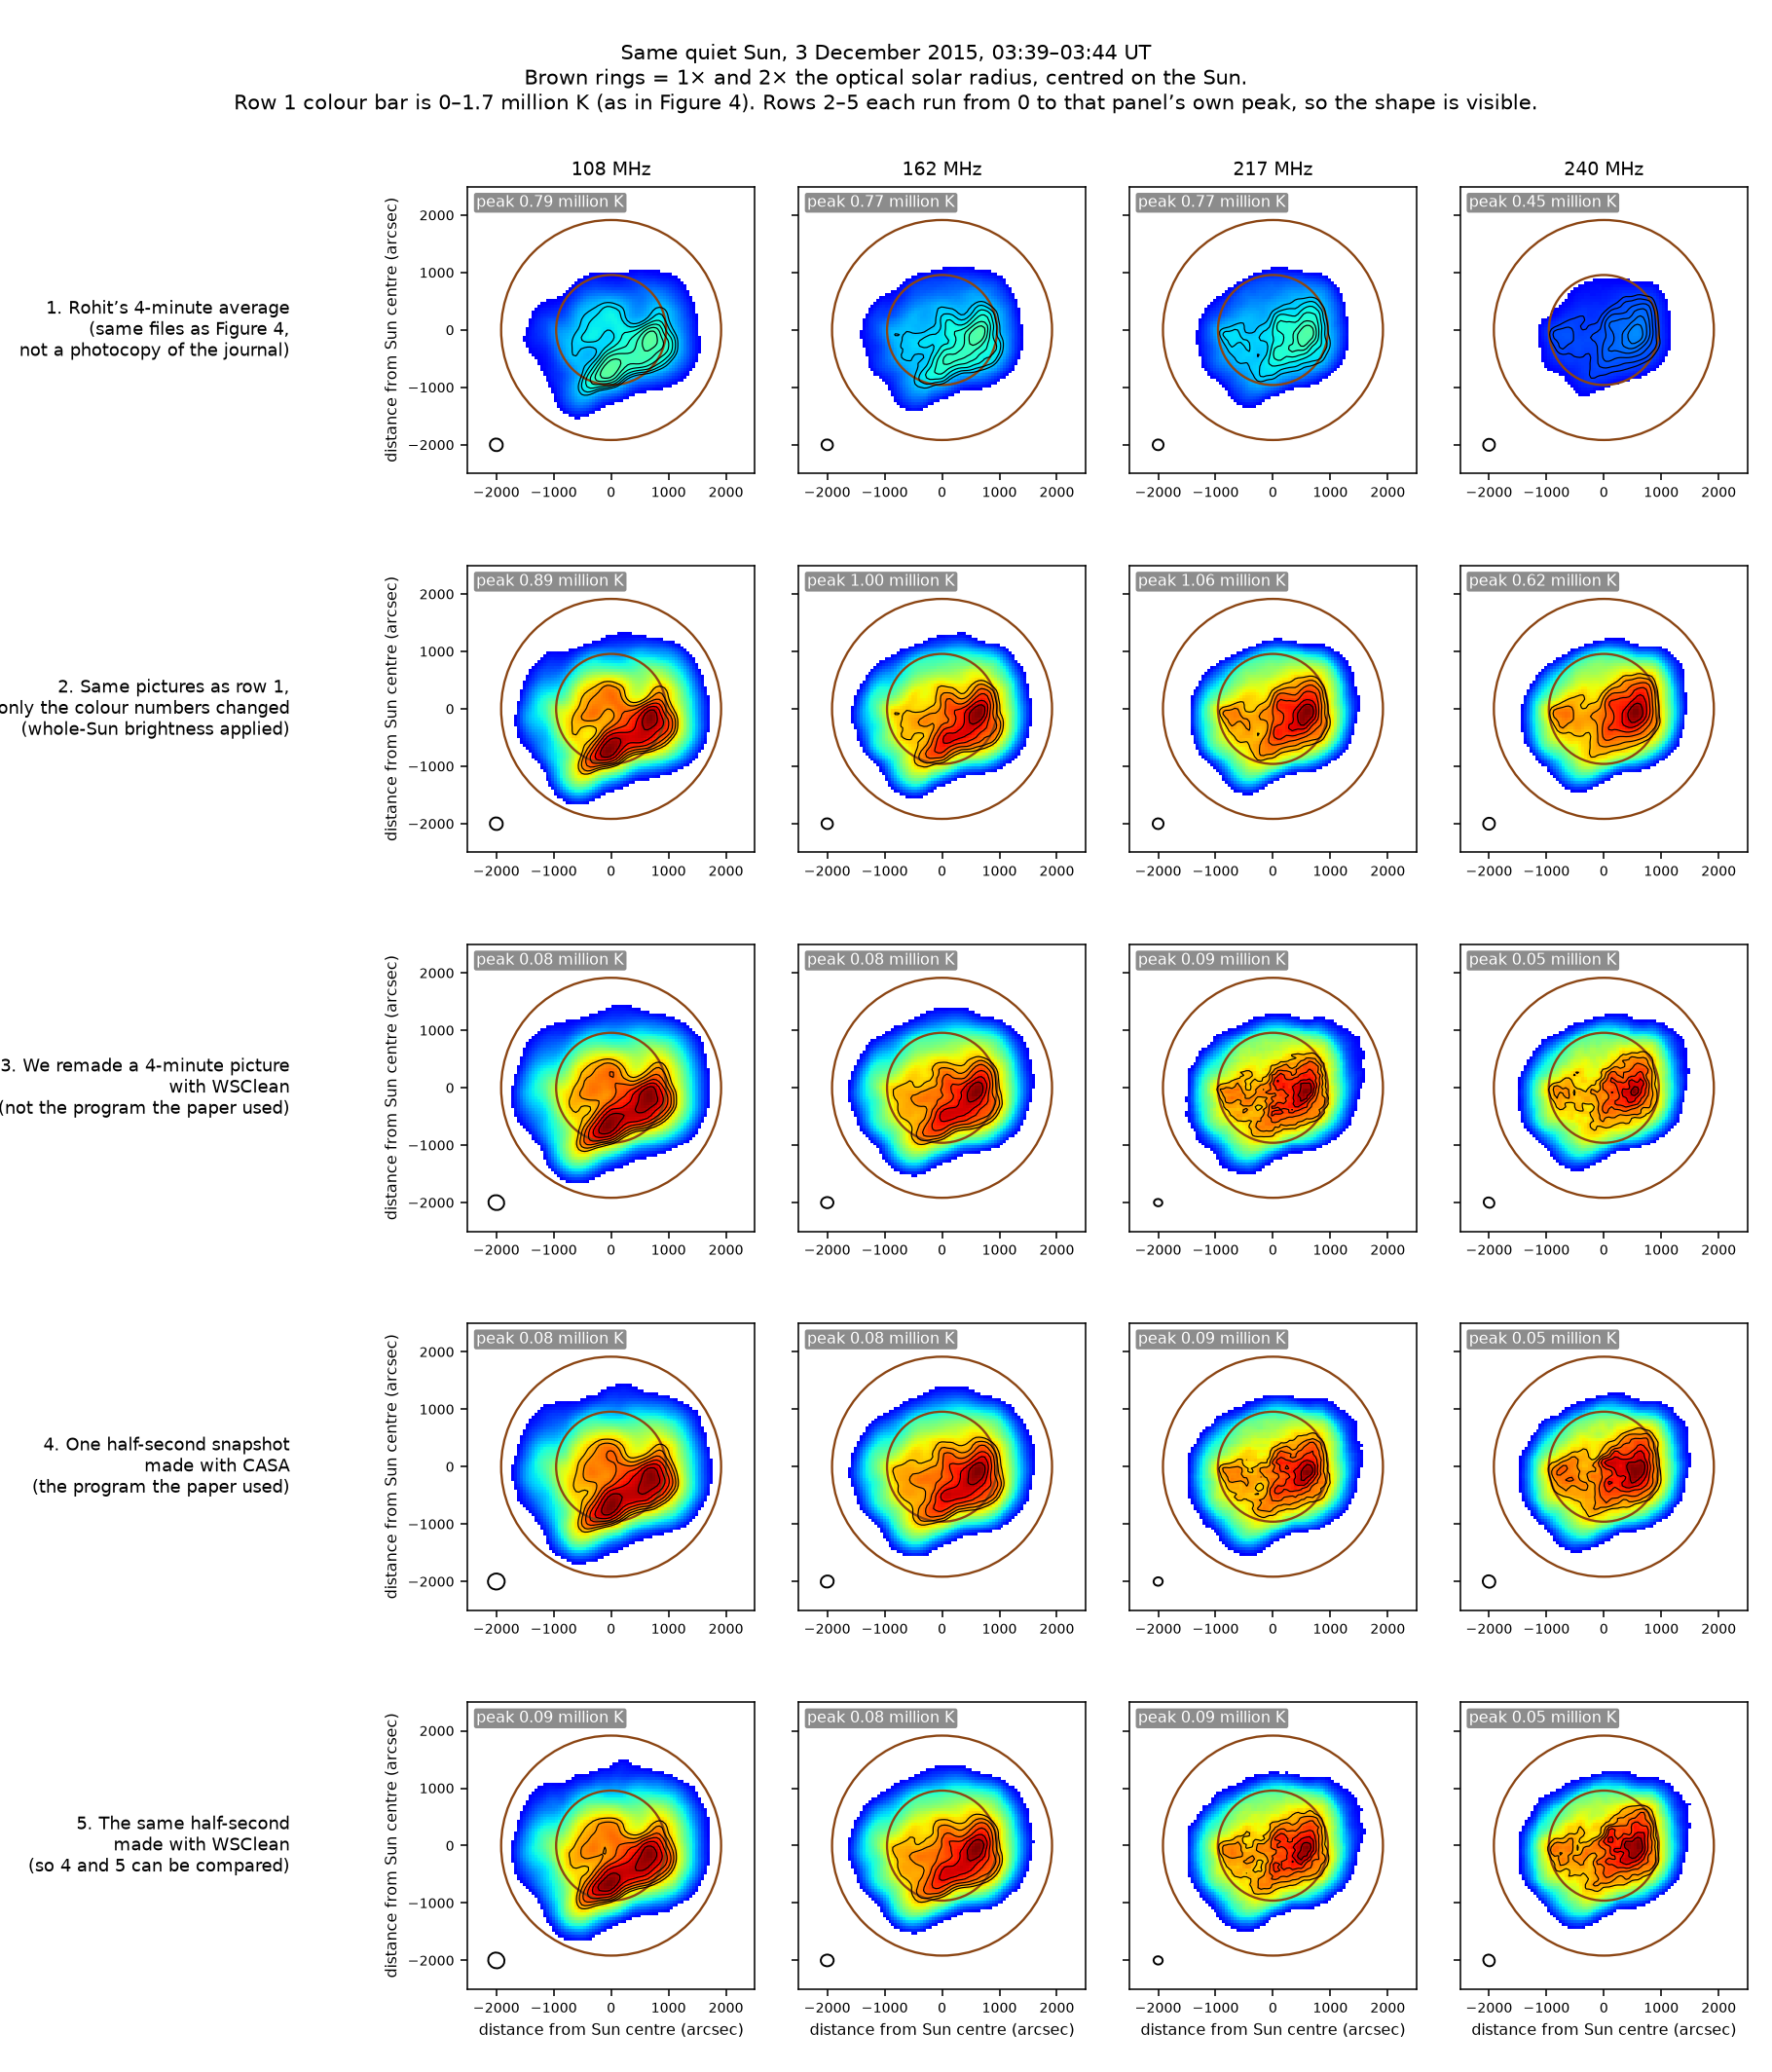

/Users/csillag/Projects/solar-burst-multiview/figures/sharma2020/compare_maps.png


In [24]:
grid = ROOT / "figures" / "sharma2020" / "compare_maps.png"
if grid.exists():
    display(Image(filename=str(grid), width=900))
    print(grid)
